# Natural frequencies of integrally stringer-stiffened cylinders: Sewall and Naumann (1968)

Sewall and Naumann [1] measured the natural frequencies of three aluminium
cylinders of nearly the same radius, skin thickness and length: an
unstiffened cylinder and two cylinders machined with 60 integral
rectangular (blade) stringers, outside the skin in one (externally
stiffened, ES) and inside in the other (internally stiffened, IS). Each was
tested with four sets of end conditions: free-free (FF), simply supported
(SS), clamped-free (CF) and clamped-clamped (CC). Their analysis, a
Rayleigh-Ritz method with the stringers averaged ("smeared") over the skin,
is plotted in their Figures 8 to 11 only; the companion analysis of Egle and
Sewall [2], with the stringers as discrete elements, tabulates the
frequencies of the "freely supported" ES cylinder (simply supported, axial
displacement free).

Here the three cylinders are modelled with discrete stringers:

- the skin with the BFSC cylinder element of Sanders-type kinematics,
  `BFSCCylinderSanders`;
- each stringer with the BFSC plate element `BFSCPlate2D` of
  [bfscplate2d](https://github.com/saullocastro/bfscplate2d), in the
  plane $(x, r)$ of the stringer, from the middle surface of the skin to the
  tip of the stringer, its nodes along the root tied to the skin.

The 60 stringers are identical and equally spaced, so that one stringer
pitch, a sector of $6°$, represents the cylinder for every circumferential
wave number $n$ (cyclic symmetry, explained below). The natural frequencies
of the problem $(\boldsymbol{K}_{C0} - \omega^2
\boldsymbol{M})\boldsymbol{u} = \boldsymbol{0}$ are compared with every
frequency of Tables II to V of [1] and with Table 2 of [2].

The model is given by the module `blade_cylinder_sector.py`, next to this
notebook, shared with the notebook of the buckling tests of Card and Jones.
Besides `bfsccylinder`, it needs `bfscplate2d`, `composites`, SciPy and
Matplotlib.

**References**

[1] Sewall, J. L.; Naumann, E. C., "An experimental and analytical
vibration study of thin cylindrical shells with and without longitudinal
stiffeners", NASA TN D-4705, September 1968.
https://ntrs.nasa.gov/citations/19680024266

[2] Egle, D. M.; Sewall, J. L., "An analysis of free vibration of
orthogonally stiffened cylindrical shells with stiffeners treated as
discrete elements", AIAA Journal 6(3), 518-526, 1968.
https://doi.org/10.2514/3.4528

In [1]:
%matplotlib inline
import time

import numpy as np
import matplotlib.pyplot as plt

from bfsccylinder.version import __version__ as bfsccylinder_version
from bfscplate2d.version import __version__ as bfscplate2d_version
from blade_cylinder_sector import (BladeCylinderSector, frequencies,
                                   axial_nodes, normalize_phase, DOF, V, W)

print('bfsccylinder', bfsccylinder_version)
print('bfscplate2d', bfscplate2d_version)

bfsccylinder 0.7.1
bfscplate2d 0.5.0


## Geometry and material

The values are those of Table I of [1] (report page 30), averages of up to
60 measurements, in inches, pounds-force and seconds. The stringers are
spaced 1.00 in along the middle surface of the skin, 60 around the
circumference, and have a fillet of radius 1/16 in on each side of the root.
The cylinder length depends on the end conditions, the length between the
supports (Table I). All cylinders are 6061-T6 aluminium alloy.

In [2]:
# Table I of [1], report page 30; lengths in in, E in psi, rho in lbf s^2/in^4
shells = {
    'unstiffened': dict(R=9.538, h=0.0255),
    'internal': dict(R=9.535, h=0.0266, height=0.2754, A_s=0.029219,
                     z_s=-0.1438),
    'external': dict(R=9.537, h=0.0256, height=0.2764, A_s=0.029319,
                     z_s=0.1439),
}
r_F = 1/16  # fillet radius
width = 0.100  # stringer width, 2 r_s
spacing = 1.00  # along the middle surface
lengths = {'FF': 25.125, 'CF': 24.625, 'SS': 24.00, 'CC': 24.00}
E = 1e7  # psi, shell and stringers
nu = 0.315
G_s = 3.8e6  # psi, shear modulus of the stringers
rho = 2.54e-4  # lbf s^2/in^4
nstringers = 60

inch = 25.4e-3  # m
psi = 4.4482216/inch**2  # Pa
print('E = %.2f GPa, G_s = %.2f GPa, E/(2 (1 + nu)) = %.3g psi'
      % (E*psi/1e9, G_s*psi/1e9, E/(2*(1 + nu))))
print('rho = %.1f kg/m^3' % (rho*4.4482216/inch**4))
for key, g in shells.items():
    print('%-11s R = %.1f mm, h = %.3f mm, 2 pi R/60 = %.3f in'
          % (key, g['R']*1e3*inch, g['h']*1e3*inch,
             2*np.pi*g['R']/nstringers))

E = 68.95 GPa, G_s = 26.20 GPa, E/(2 (1 + nu)) = 3.8e+06 psi
rho = 2714.5 kg/m^3
unstiffened R = 242.3 mm, h = 0.648 mm, 2 pi R/60 = 0.999 in
internal    R = 242.2 mm, h = 0.676 mm, 2 pi R/60 = 0.999 in
external    R = 242.2 mm, h = 0.650 mm, 2 pi R/60 = 0.999 in


Table I gives the shear modulus of the stringers $G_s = E/[2(1 + \nu)]$
within 0.1 %, so that the stringers are isotropic, as the plate elements
are. The 60 stringers fill the circumference with the spacing of 1.00 in.

**Stringer model.** The "stiffener height" of Table I is measured from the
surface of the skin: with this datum, the rectangle $0.100 \times$ height
plus the two fillets, of area $(1 - \pi/4)r_F^2$ each, give the area $A_s$
and the centroid distance $\bar{z}_s$ of Table I, as checked below. The plate
of a stringer goes from the middle surface of the skin to the tip, of height
$H_s = \text{height} + h/2$ and thickness $b_s = 0.100$ in; the fillets are
not modelled.

In [3]:
for side in ['internal', 'external']:
    g = shells[side]
    rect = width*g['height']
    fillets = 2*(1 - np.pi/4)*r_F**2
    # centroid of a fillet from the skin surface, (10 - 3 pi)/(12 - 3 pi) r_F
    zf = (10 - 3*np.pi)/(12 - 3*np.pi)*r_F
    zbar = (g['h']/2 + (rect*g['height']/2 + fillets*zf)/(rect + fillets))
    Hs = g['height'] + g['h']/2
    print('%s: rectangle + fillets: A = %.6f in^2 (A_s = %.6f), '
          'z = %.4f in (|z_s| = %.4f)' % (side, rect + fillets, g['A_s'],
                                          zbar, abs(g['z_s'])))
    print('    plate of the model: H_s = %.4f in, b_s H_s = %.5f in^2 '
          '(%+.1f %% of A_s), centroid H_s/2 = %.4f in'
          % (Hs, width*Hs, 100*(width*Hs/g['A_s'] - 1), Hs/2))

internal: rectangle + fillets: A = 0.029217 in^2 (A_s = 0.029219), z = 0.1439 in (|z_s| = 0.1438)
    plate of the model: H_s = 0.2887 in, b_s H_s = 0.02887 in^2 (-1.2 % of A_s), centroid H_s/2 = 0.1443 in
external: rectangle + fillets: A = 0.029317 in^2 (A_s = 0.029319), z = 0.1439 in (|z_s| = 0.1439)
    plate of the model: H_s = 0.2892 in, b_s H_s = 0.02892 in^2 (-1.4 % of A_s), centroid H_s/2 = 0.1446 in


## Measured frequencies

Tables II to V of [1] (report pages 31 and 32) give the resonant frequencies
in Hz for $m$ axial and $n$ circumferential wave numbers. The circumferential
wave number $n$ is the number of full waves around the circumference. The
axial wave number $m$ is defined in Figure 4 of [1] (report page 37) by the
radial mode shape along the length: for SS and CC ends, $m$ half-waves
($m - 1$ nodal circles between the ends); for CF ends, $m - 1$ nodal circles
between the clamped and the free end; for FF ends, $m$ nodal circles ($m =
0$, uniform along the length; $m = 1$, linear, one nodal circle; $m = 2$, two
nodal circles).

Two values of the same $(m, n)$ in a table are "dual resonances", two
frequencies of two mode orientations a quarter wavelength apart, found for
many modes [1]. Table III (FF) gives two values for every $m = 0$ and $m =
1$ mode: the first measured with the electrodynamic shaker, the second with
an air shaker, used for small $m$ and $n$, whose frequencies [1] (report
page 10) considers "more nearly correct over the range of $n$ values
covered"; the values with $m \ge 2$ are single values, from the
electrodynamic shaker.

In [4]:
# test[bc][shell][(m, n)] = list of frequencies in Hz
test = {bc: {} for bc in ['SS', 'FF', 'CC', 'CF']}

# Table II, simply supported, report page 31
test['SS']['unstiffened'] = {
    (1, 4): [287.0], (1, 5): [203.0, 211.0], (1, 6): [175.0],
    (1, 7): [163.0, 169.0], (1, 8): [188.0], (1, 9): [224.0],
    (1, 10): [268.0], (1, 11): [326.0], (1, 12): [382.0, 385.0],
    (1, 13): [440.0], (1, 15): [590.0],
    (2, 8): [345.0, 346.0], (2, 10): [339.0, 342.0], (2, 11): [369.0, 370.0],
    (2, 12): [409.0, 411.0], (2, 13): [471.0, 479.0],
    (3, 11): [491.0, 507.0], (3, 12): [510.0, 517.0], (3, 14): [604.0],
}
test['SS']['internal'] = {
    (1, 4): [233.0], (1, 5): [175.0], (1, 6): [137.0, 147.0],
    (1, 7): [142.0, 150.0], (1, 8): [169.0], (1, 9): [203.0],
    (1, 10): [243.0], (1, 11): [290.0], (1, 12): [333.0], (1, 13): [392.0],
    (1, 14): [450.0], (1, 15): [502.0],
    (2, 8): [319.0], (2, 9): [333.0], (2, 10): [366.0], (2, 11): [399.0],
    (2, 12): [443.0], (2, 13): [482.0], (2, 14): [551.0, 560.0],
    (3, 8): [602.0, 605.0], (3, 11): [622.0], (3, 12): [664.0],
    (3, 14): [761.0],
}
test['SS']['external'] = {
    (1, 5): [231.0], (1, 6): [197.0, 201.0], (1, 7): [189.0],
    (1, 8): [199.0], (1, 9): [219.0], (1, 10): [252.0], (1, 11): [290.0],
    (1, 12): [336.0], (1, 13): [378.0, 386.0], (1, 14): [440.0],
    (1, 15): [500.0],
    (2, 10): [469.0, 478.0], (2, 11): [489.0], (2, 12): [507.0, 512.0],
    (2, 13): [546.0], (2, 14): [590.0], (2, 15): [630.0],
}

# Table III, free-free, report page 31: m = 0 and 1 as
# (electrodynamic shaker, air shaker); m >= 2 electrodynamic shaker only
test['FF']['unstiffened'] = {
    (0, 2): (11.8, 7.2), (0, 3): (24.5, 20.1), (0, 4): (40.1, 37.9),
    (0, 5): (63.4, 61.9), (0, 6): (91.7, 91.6), (0, 7): (125.6, 125.0),
    (0, 8): (165.0, 165.0), (0, 9): (210.0, 210.0), (0, 10): (262.0, 262.0),
    (0, 11): (318.0, 318.0), (0, 12): (378.0, 378.0),
    (0, 13): (443.0, 443.0), (0, 14): (512.0, 512.0),
    (1, 2): (14.8, 9.2), (1, 3): (26.8, 22.3), (1, 4): (44.6, 40.3),
    (1, 5): (66.8, 65.0), (1, 6): (94.8, 94.6), (1, 7): (129.0, 129.0),
    (1, 8): (170.0, 170.0), (1, 9): (214.0, 214.0), (1, 10): (266.0, 266.0),
    (1, 11): (322.0, 322.0), (1, 12): (382.0, 382.0),
    (1, 13): (452.0, 452.0), (1, 14): (521.0, 521.0),
    (2, 5): (367.0,), (2, 6): (292.0,), (2, 7): (242.0,), (2, 8): (235.0,),
    (2, 9): (252.0,), (2, 10): (290.0,), (2, 11): (339.0,),
    (2, 13): (459.0,), (2, 14): (533.0,),
    (3, 13): (501.0,), (3, 14): (564.0,),
}
test['FF']['internal'] = {
    (0, 2): (5.0, 6.1), (0, 3): (18.0, 16.1), (0, 4): (32.0, 30.4),
    (0, 5): (51.3, 51.1), (0, 6): (74.0, 74.0), (0, 7): (102.0, 102.0),
    (0, 8): (132.0, 132.0), (0, 9): (170.0, 170.0), (0, 10): (210.0, 210.0),
    (0, 11): (255.0, 255.0), (0, 12): (302.0, 302.0),
    (0, 13): (351.0, 351.0), (0, 14): (410.0, 410.0),
    (1, 2): (21.0, 15.8), (1, 3): (35.0, 31.4), (1, 4): (52.0, 50.4),
    (1, 5): (71.0, 70.3), (1, 6): (96.0, 95.8), (1, 7): (124.0, 124.0),
    (1, 8): (158.0, 158.0), (1, 9): (195.0, 195.0), (1, 10): (234.0, 234.0),
    (1, 11): (280.0, 280.0), (1, 12): (330.0, 330.0),
    (1, 13): (382.0, 382.0),
    (2, 6): (273.0,), (2, 7): (245.0,), (2, 8): (252.0,), (2, 9): (276.0,),
    (2, 10): (312.0,), (2, 11): (358.0,), (2, 12): (405.0,),
    (2, 13): (455.0,),
}
test['FF']['external'] = {
    (0, 2): (4.8, 5.9), (0, 3): (17.5, 15.7), (0, 4): (30.8, 30.6),
    (0, 5): (50.0, 50.1), (0, 6): (71.0, 71.0), (0, 7): (98.0, 98.0),
    (0, 8): (129.0, 129.0), (0, 9): (165.0, 165.0), (0, 10): (208.0, 208.0),
    (0, 11): (249.0, 249.0), (0, 12): (295.0, 295.0),
    (0, 13): (348.0, 348.0), (0, 14): (403.0, 403.0),
    (1, 2): (20.5, 15.2), (1, 3): (34.5, 31.1), (1, 4): (52.5, 49.4),
    (1, 5): (72.0, 69.7), (1, 6): (94.0, 94.0), (1, 7): (122.0, 122.0),
    (1, 8): (159.0, 159.0), (1, 9): (189.0, 189.0), (1, 10): (232.0, 232.0),
    (1, 11): (273.0, 273.0), (1, 12): (318.0, 318.0),
    (1, 14): (430.0, 430.0), (1, 15): (493.0, 493.0),
    (2, 8): (320.0,), (2, 9): (330.0,), (2, 10): (352.0,), (2, 11): (388.0,),
    (2, 12): (422.0,), (2, 13): (470.0,),
}

# Table IV, clamped-clamped, report page 32
test['CC']['unstiffened'] = {
    (1, 5): [321.0, 325.0], (1, 6): [263.0], (1, 7): [233.0],
    (1, 8): [227.0], (1, 9): [244.0], (1, 10): [281.0], (1, 12): [386.0],
    (1, 13): [453.0], (1, 14): [515.0],
    (2, 7): [479.0], (2, 8): [418.0, 423.0], (2, 11): [397.0, 404.0],
    (2, 13): [490.0], (2, 14): [552.0], (2, 15): [622.0],
    (3, 10): [583.0], (3, 11): [562.0], (3, 15): [690.0],
}
test['CC']['internal'] = {
    (1, 4): [356.0], (1, 5): [275.0], (1, 6): [228.0], (1, 7): [207.0],
    (1, 8): [212.0], (1, 9): [231.0], (1, 10): [262.0],
    (1, 11): [302.0, 308.0], (1, 12): [356.0], (1, 13): [405.0],
    (1, 14): [457.0], (1, 15): [522.0],
    (2, 7): [449.0], (2, 8): [423.0], (2, 9): [418.0], (2, 10): [435.0],
    (2, 11): [467.0], (2, 13): [551.0], (2, 14): [603.0], (2, 15): [660.0],
    (3, 12): [757.0, 763.0], (3, 13): [803.0], (3, 14): [846.0],
}
test['CC']['external'] = {
    (1, 5): [347.0], (1, 6): [313.0], (1, 7): [282.0], (1, 8): [272.0],
    (1, 9): [287.0], (1, 10): [305.0], (1, 11): [333.0], (1, 12): [370.0],
    (1, 14): [466.0], (1, 15): [525.0],
    (2, 10): [578.0], (2, 12): [605.0], (2, 13): [630.0], (2, 15): [711.0],
}

# Table V, clamped-free, report page 32
test['CF']['unstiffened'] = {
    (1, 3): [155.0, 157.0], (1, 4): [107.0], (1, 5): [89.0, 91.0],
    (1, 6): [102.0], (1, 7): [130.0], (1, 8): [166.0], (1, 9): [208.0],
    (1, 10): [260.0], (1, 11): [317.0], (1, 12): [374.0], (1, 14): [523.0],
    (2, 5): [341.0], (2, 6): [276.0], (2, 7): [240.0], (2, 8): [227.0, 231.0],
    (2, 9): [246.0], (2, 10): [281.0], (2, 11): [337.0],
    (2, 12): [393.0, 396.0], (2, 13): [455.0, 461.0], (2, 14): [531.0],
    (2, 15): [603.0],
    (3, 9): [400.0], (3, 11): [409.0, 412.0], (3, 13): [476.0],
    (3, 14): [558.0], (3, 15): [633.0],
}
test['CF']['internal'] = {
    (1, 3): [147.0], (1, 4): [99.0], (1, 5): [80.0, 83.0],
    (1, 6): [90.0, 93.0], (1, 7): [113.0], (1, 8): [143.0], (1, 9): [177.0],
    (1, 10): [217.0], (1, 11): [267.0], (1, 12): [312.0], (1, 13): [363.0],
    (1, 14): [425.0], (1, 15): [486.0],
    (2, 4): [390.0], (2, 5): [303.0], (2, 6): [247.0], (2, 7): [225.0],
    (2, 8): [233.0], (2, 9): [257.0], (2, 10): [290.0, 295.0],
    (2, 11): [331.0], (2, 12): [384.0], (2, 13): [438.0], (2, 14): [494.0],
    (2, 15): [535.0],
    (3, 6): [544.0], (3, 9): [434.0], (3, 10): [456.0], (3, 11): [491.0],
    (3, 12): [524.0], (3, 13): [584.0], (3, 14): [627.0],
}
test['CF']['external'] = {
    (1, 2): [277.0], (1, 3): [161.0, 166.0], (1, 4): [110.0, 114.0],
    (1, 5): [94.0, 97.0], (1, 6): [100.0], (1, 7): [121.0], (1, 8): [147.0],
    (1, 9): [181.0], (1, 10): [217.0, 222.0], (1, 11): [259.0],
    (1, 12): [316.0], (1, 13): [360.0], (1, 14): [418.0], (1, 15): [495.0],
    (2, 4): [473.0], (2, 5): [377.0], (2, 6): [340.0], (2, 7): [308.0, 310.0],
    (2, 8): [298.0, 301.0], (2, 10): [328.0, 330.0], (2, 11): [365.0],
    (2, 13): [444.0], (2, 15): [544.0],
}


def reference(bc, m, values):
    # value compared: the air-shaker value for FF, m = 0 and 1 ([1], report
    # page 10), otherwise the mean of a dual resonance
    if bc == 'FF':
        return values[1] if len(values) == 2 else values[0]
    return np.mean(values)


print('number of measured (m, n):')
for bc in test:
    print('  %s: ' % bc + ', '.join('%s %d' % (s, len(test[bc][s]))
                                   for s in test[bc]))

number of measured (m, n):
  SS: unstiffened 19, internal 23, external 17
  FF: unstiffened 37, internal 33, external 32
  CC: unstiffened 18, internal 23, external 14
  CF: unstiffened 27, internal 32, external 23


## Model: one stringer pitch with cyclic symmetry

The cylinder is invariant under a rotation by $\phi = 2\pi/60$ about its
axis. The model is the sector $0 \le \theta \le \phi$, with the stringer at
its middle, $\theta = \phi/2$; its skin has `nbay` elements across the
sector and `nx` nodes along $x$, its stringer `nh` elements along the
height. The degrees of freedom of the BFSC elements are in the axial,
circumferential and radial directions, which rotate with the sector, so that
a mode of the whole cylinder with $n$ circumferential waves has, in the
sector $k$, the degrees of freedom of the sector $0$ multiplied by $e^{i n k
\phi}$. The nodes of the edge $\theta = \phi$ are eliminated with
$\boldsymbol{u}(\phi) = e^{i n \phi}\boldsymbol{u}(0)$, and one complex
Hermitian eigenvalue problem per harmonic $n = 0, 1, \ldots, 30$ gives all
the modes of the cylinder. A harmonic $n$ contains the circumferential waves
$n \pm 60 j$, which the discrete stringers couple, as Egle and Sewall [2]
show for discrete stringers; with 60 stringers the coupling of a mode with
$n \le 15$ to the waves $60 - n$ and beyond is weak [2], but it is in the
model. The modes of $n$ and $-n$ are the pair in $\cos n\theta$ and $\sin
n\theta$ of the same frequency: the discrete model with identical stringers
has no dual resonances for $n < 30$. In the tests, [1] (report page 11)
does not know whether the preferred orientations of the dual resonances "are
due to construction defects or to rotational and translational energies of
the stiffeners"; departures from the ideal geometry, such as the two
longitudinal seams $180°$ apart (report page 6), would split the pair.

The stringer root is tied to the skin along $\theta = \phi/2$: the axial,
radial and circumferential displacements and the rotation about $x$ of the
stringer are those of the skin, $U = u$, $V = w$, $W = v$, $W_{,Y} =
-w_{,y} + v/R$, with the rotation of the Sanders-type kinematics, and the
derivatives of these relations along $x$; see the docstring of
`blade_cylinder_sector.py`.

The end conditions of the tests [1] (report pages 6 to 8) and their model:

| tests | model at the end |
|---|---|
| free-free: suspended by soft rubber bands | none |
| simply supported: rings with sharp tips inside and outside the skin at each end, which restrain the normal displacement and let the cylinder move axially; for the stiffened cylinders, clips at three locations between stringers against the rotation of the cylinder; "motion normal to the shell between stiffeners was not restrained on the stiffened side of the shell" (report page 7) | $v = w = 0$; $u$, $w_{,x}$ free; $V = W = 0$ along the end edge of the stringer |
| clamped: the end potted 1/2 in deep in a groove of an end plate | $u = v = w = w_{,x} = 0$ and the end edge of the stringer clamped |

The derivatives along an end edge of its constrained displacements are
constrained as well. With SS ends and $n = 0$, the mean of $u$ along the
edge $x = 0$ is tied to zero, which removes the axial rigid-body motion. With
FF ends, the six rigid-body motions of the cylinder appear as zero
frequencies at $n = 0$ and $n = 1$; the tests start at $n = 2$.

Each mode is identified by its harmonic $n$ and by the number of sign
changes along $x$ of the normal displacement $w$ of the skin, on the line of
the sector where $w$ is largest, counted as in Figure 4 of [1]: $m$ = sign
changes + 1 for SS, CC and CF ends, $m$ = sign changes for FF ends. For each
$(m, n)$ the lowest frequency is kept.

In [5]:
def build(shell, bc, nx, nbay, nh):
    g = shells[shell]
    blade = {}
    if shell != 'unstiffened':
        blade = dict(bs=width, Hs=g['height'] + g['h']/2, side=shell, nh=nh)
    return BladeCylinderSector(R=g['R'], L=lengths[bc], h=g['h'], E=E,
                               nu=nu, rho=rho, nstringers=nstringers, nx=nx,
                               nbay=nbay, **blade)


def spectrum(shell, bc, mesh, ns=range(2, 17), k=10):
    # lowest frequency and mode of each (m, n)
    model = build(shell, bc, *mesh)
    freq, modes = {}, {}
    for n in ns:
        f, X = frequencies(model, bc, n, k=k)
        for i, fi in enumerate(f):
            if fi < 1.:  # rigid-body motions, FF
                continue
            m = axial_nodes(model, X[:, i]) + (0 if bc == 'FF' else 1)
            if (m, n) not in freq:
                freq[(m, n)] = fi
                modes[(m, n)] = X[:, i]
    return model, freq, modes

## Mesh convergence

The three cylinders and the four end conditions with a sequence of meshes
`(nx, nbay, nh)`. For each case the table gives the number of complex
degrees of freedom of the sector, the frequency of the lowest measured mode
of Tables II to V, and the largest change, over all the measured $(m, n)$ of
the case, from the previous mesh. The FF modes with $m = 1$ and small $n$,
in which the cylinder twists between its free ends, converge slowly along
$x$ and need a finer mesh along $x$ than the other end conditions.

In [6]:
coarse = [(13, 2, 2), (25, 4, 3), (49, 8, 6), (97, 12, 8)]
meshes = {'SS': coarse, 'CC': coarse, 'CF': coarse,
          'FF': [(49, 8, 6), (97, 8, 6), (145, 8, 6), (193, 8, 6), (241, 8, 6)]}
final = {bc: meshes[bc][-1] for bc in meshes}
conv = {}
t0 = time.time()
for shell in ['unstiffened', 'internal', 'external']:
    for bc in ['SS', 'FF', 'CC', 'CF']:
        for mesh in meshes[bc]:
            conv[(shell, bc, mesh)] = spectrum(shell, bc, mesh)
print('%.0f s' % (time.time() - t0))

print('cylinder    ends  mesh            dofs  lowest tested mode   '
      'largest change of the tested modes')
for shell in ['unstiffened', 'internal', 'external']:
    for bc in ['SS', 'FF', 'CC', 'CF']:
        keys = list(test[bc][shell])
        mn0 = min(keys, key=lambda mn: reference(bc, mn[0],
                                                 test[bc][shell][mn]))
        prev = None
        for mesh in meshes[bc]:
            model, freq, _ = conv[(shell, bc, mesh)]
            f = np.array([freq.get(mn, np.nan) for mn in keys])
            change = ''
            if prev is not None:
                d = np.abs(f/prev - 1)
                i = np.nanargmax(d)
                change = '%5.2f %% at (%d, %2d)' % (100*d[i], *keys[i])
            print('%-11s %-5s %-13s %5d  (%d, %2d) %7.1f Hz     %s'
                  % (shell, bc, mesh, model.Nr, *mn0, freq.get(mn0, np.nan),
                     change))
            prev = f

4294 s
cylinder    ends  mesh            dofs  lowest tested mode   largest change of the tested modes
unstiffened SS    (13, 2, 2)      260  (1,  7)   168.7 Hz     
unstiffened SS    (25, 4, 3)     1000  (1,  7)   166.8 Hz      1.74 % at (3, 11)
unstiffened SS    (49, 8, 6)     3920  (1,  7)   166.3 Hz      0.33 % at (3, 11)
unstiffened SS    (97, 12, 8)   11640  (1,  7)   166.2 Hz      0.08 % at (3, 11)
unstiffened FF    (49, 8, 6)     3920  (0,  2)     7.2 Hz     
unstiffened FF    (97, 8, 6)     7760  (0,  2)     7.2 Hz     14.68 % at (1,  2)
unstiffened FF    (145, 8, 6)   11600  (0,  2)     7.2 Hz      3.54 % at (1,  2)
unstiffened FF    (193, 8, 6)   15440  (0,  2)     7.2 Hz      1.32 % at (1,  2)
unstiffened FF    (241, 8, 6)   19280  (0,  2)     7.2 Hz      0.63 % at (1,  2)
unstiffened CC    (13, 2, 2)      260  (1,  8)   238.5 Hz     
unstiffened CC    (25, 4, 3)     1000  (1,  8)   236.2 Hz      1.97 % at (3, 11)
unstiffened CC    (49, 8, 6)     3920  (1,  8)   235.7 Hz   

The finest mesh of each end condition is used below: from the previous
mesh, the measured modes change by less than 1 % (the last line of each
case in the table).

## Comparison with the tests

All three cylinders and the four end conditions with the finest mesh:

In [7]:
results = {(shell, bc): conv[(shell, bc, final[bc])]
           for shell in ['unstiffened', 'internal', 'external']
           for bc in ['SS', 'FF', 'CC', 'CF']}

summary = {}
for bc, table in [('SS', 'II'), ('FF', 'III'), ('CC', 'IV'), ('CF', 'V')]:
    print('\nEnd conditions %s, Table %s of [1]' % (bc, table))
    print(' m   n | %-26s | %-26s | %-26s' % ('unstiffened', 'internal',
                                              'external'))
    print('       | ' + ' | '.join(['  test (Hz)  FE (Hz)  diff'] * 3))
    keys = sorted(set().union(*[test[bc][s] for s in test[bc]]))
    for m, n in keys:
        row = []
        for shell in ['unstiffened', 'internal', 'external']:
            values = test[bc][shell].get((m, n))
            if values is None:
                row.append(' '*26)
                continue
            ref = reference(bc, m, values)
            fe = results[(shell, bc)][1].get((m, n), np.nan)
            row.append('%11.1f %8.1f %+5.1f%%' % (ref, fe,
                                                    100*(fe/ref - 1)))
            summary.setdefault((shell, bc), []).append(fe/ref - 1)
        print('%2d %3d | ' % (m, n) + ' | '.join(row))


End conditions SS, Table II of [1]
 m   n | unstiffened                | internal                   | external                  
       |   test (Hz)  FE (Hz)  diff |   test (Hz)  FE (Hz)  diff |   test (Hz)  FE (Hz)  diff
 1   4 |       287.0    287.6  +0.2% |       233.0    233.2  +0.1% |                           
 1   5 |       207.0    201.8  -2.5% |       175.0    165.2  -5.6% |       231.0    228.5  -1.1%
 1   6 |       175.0    166.6  -4.8% |       142.0    139.7  -1.6% |       199.0    195.8  -1.6%
 1   7 |       166.0    166.2  +0.1% |       146.0    142.4  -2.4% |       189.0    186.2  -1.5%
 1   8 |       188.0    189.3  +0.7% |       169.0    161.8  -4.3% |       199.0    192.9  -3.1%
 1   9 |       224.0    226.8  +1.3% |       203.0    190.4  -6.2% |       219.0    211.1  -3.6%
 1  10 |       268.0    274.0  +2.3% |       243.0    224.9  -7.4% |       252.0    237.7  -5.7%
 1  11 |       326.0    328.6  +0.8% |       290.0    264.0  -9.0% |       290.0    270.7  -6.6%
 

The relative difference is (FE − test)/test; a dual resonance is compared
with the mean of its two frequencies, the FF modes with $m = 0$ and $m = 1$
with the air-shaker value. The statistics of the relative differences per
cylinder and end conditions:

In [8]:
print('cylinder     ends  modes   mean diff   min diff   max diff')
for (shell, bc), d in summary.items():
    d = 100*np.array(d)
    print('%-12s %-4s %5d   %+7.1f %%  %+7.1f %%  %+7.1f %%'
          % (shell, bc, len(d), d.mean(), d.min(), d.max()))

cylinder     ends  modes   mean diff   min diff   max diff
unstiffened  SS      19      +0.6 %     -4.8 %     +3.7 %
internal     SS      23      -4.9 %    -10.3 %     +0.1 %
external     SS      17      -4.3 %    -10.2 %     -0.6 %
unstiffened  FF      37      +1.7 %     -3.5 %     +7.5 %
internal     FF      33      -6.7 %    -14.9 %     +2.3 %
external     FF      32      -6.6 %    -15.4 %     +3.5 %
internal     CC      23      -3.4 %     -9.3 %     +0.4 %
unstiffened  CC      18      +2.7 %     -1.7 %     +8.4 %
external     CC      14      -0.1 %     -8.8 %     +5.2 %
external     CF      23      -4.3 %    -15.2 %     +3.7 %
unstiffened  CF      27      +2.5 %     +0.1 %     +7.8 %
internal     CF      32      -5.7 %    -11.0 %     -0.6 %


## Circumferential bending stiffness of the skin at the stringer roots

In the model each stringer is joined to the skin along a line, and the skin
has the thickness $h$ everywhere. The actual roots, 0.100 in wide with
fillets of radius 1/16 in on both sides, stiffen the skin in circumferential
bending over about a fifth of each 1.00 in bay. Appendix A of [1] (report
pages 23 to 26) estimates this effect, by an equal-strain-energy argument for
a skin in pure circumferential bending, as an increase of the circumferential
bending stiffness of the skin by the factor $D_y/D = 1.195$ (internal
stringers) and $1.197$ (external stringers), on which the analytical
frequencies of Figures 8 to 11 of [1] are based (report page 25); Table 1
of [2] uses $D_y/D = 1.197$ as well. According to [1] (report page 17) the
effect grows with $n$, about 9 % for $m = 1$, $n = 15$ (SS). The modes that
bend the skin around the circumference without stretching it, the FF modes
with $m = 0$ and $m = 1$, in which the stringers add mass but little
stiffness, should be sensitive to it too.

As a variant, the stiffened cylinders are analysed again with these factors
applied to the circumferential bending stiffness $D_{22}$ of the skin
elements (`Dy_factor`), everything else unchanged. This is the correction of
[1], smeared over the whole skin, not a model of the root geometry.

In [9]:
Dy = {'internal': 1.195, 'external': 1.197}  # [1], appendix A, page 25


def spectrum_Dy(shell, bc, mesh, ns=range(2, 17), k=10):
    g = shells[shell]
    model = BladeCylinderSector(R=g['R'], L=lengths[bc], h=g['h'], E=E,
                                nu=nu, rho=rho, nstringers=nstringers,
                                nx=mesh[0], nbay=mesh[1], bs=width,
                                Hs=g['height'] + g['h']/2, side=shell,
                                nh=mesh[2], Dy_factor=Dy[shell])
    freq = {}
    for n in ns:
        f, X = frequencies(model, bc, n, k=k)
        for i, fi in enumerate(f):
            if fi < 1.:
                continue
            m = axial_nodes(model, X[:, i]) + (0 if bc == 'FF' else 1)
            freq.setdefault((m, n), fi)
    return freq


t0 = time.time()
results_Dy = {(shell, bc): spectrum_Dy(shell, bc, final[bc])
              for shell in ['internal', 'external']
              for bc in ['SS', 'FF', 'CC', 'CF']}
print('%.0f s' % (time.time() - t0))

print('cylinder  ends  modes  (FE - test)/test, D_y/D = 1    '
      'D_y/D of [1]')
print('                       mean    min     max          '
      'mean    min     max')
summary_Dy = {}
for shell in ['internal', 'external']:
    for bc in ['SS', 'FF', 'CC', 'CF']:
        d0, d1 = [], []
        for (m, n), values in test[bc][shell].items():
            ref = reference(bc, m, values)
            d0.append(results[(shell, bc)][1].get((m, n), np.nan)/ref - 1)
            d1.append(results_Dy[(shell, bc)].get((m, n), np.nan)/ref - 1)
        d0, d1 = 100*np.array(d0), 100*np.array(d1)
        summary_Dy[(shell, bc)] = d1
        print('%-9s %-4s %5d  %+6.1f %+6.1f %+6.1f       %+6.1f %+6.1f '
              '%+6.1f' % (shell, bc, len(d0), np.nanmean(d0), np.nanmin(d0),
                          np.nanmax(d0), np.nanmean(d1), np.nanmin(d1),
                          np.nanmax(d1)))

2098 s
cylinder  ends  modes  (FE - test)/test, D_y/D = 1    D_y/D of [1]
                       mean    min     max          mean    min     max
internal  SS      23    -4.9  -10.3   +0.1         -1.0   -4.9   +1.7
internal  FF      33    -6.7  -14.9   +2.3         -0.7   -7.0   +4.7
internal  CC      23    -3.4   -9.3   +0.4         -0.2   -2.4   +2.0
internal  CF      32    -5.7  -11.0   -0.6         -1.4   -5.4   +1.1
external  SS      17    -4.3  -10.2   -0.6         -0.3   -3.1   +1.3
external  FF      32    -6.6  -15.4   +3.5         -0.4   -7.5   +5.8
external  CC      14    -0.1   -8.8   +5.2         +2.8   -2.4   +6.9
external  CF      23    -4.3  -15.2   +3.7         -0.2   -7.6   +3.9


The simply supported cylinders mode by mode, $m = 1$, with both skins:

In [10]:
print(' n   internal: test   FE   FE(D_y)       external: test   FE   '
      'FE(D_y)')
for n in range(4, 16):
    row = '%2d ' % n
    for shell in ['internal', 'external']:
        values = test['SS'][shell].get((1, n))
        if values is None:
            row += ' '*34
            continue
        ref = reference('SS', 1, values)
        f0 = results[(shell, 'SS')][1][(1, n)]
        f1 = results_Dy[(shell, 'SS')][(1, n)]
        row += ('      %6.1f %6.1f (%+5.1f%%) %6.1f (%+5.1f%%)'
                % (ref, f0, 100*(f0/ref - 1), f1, 100*(f1/ref - 1)))
    print(row)

 n   internal: test   FE   FE(D_y)       external: test   FE   FE(D_y)
 4        233.0  233.2 ( +0.1%)  233.6 ( +0.2%)                                  
 5        175.0  165.2 ( -5.6%)  166.5 ( -4.9%)       231.0  228.5 ( -1.1%)  229.4 ( -0.7%)
 6        142.0  139.7 ( -1.6%)  142.9 ( +0.6%)       199.0  195.8 ( -1.6%)  197.9 ( -0.5%)
 7        146.0  142.4 ( -2.4%)  148.1 ( +1.5%)       189.0  186.2 ( -1.5%)  190.4 ( +0.7%)
 8        169.0  161.8 ( -4.3%)  170.3 ( +0.8%)       199.0  192.9 ( -3.1%)  199.7 ( +0.4%)
 9        203.0  190.4 ( -6.2%)  202.0 ( -0.5%)       219.0  211.1 ( -3.6%)  221.1 ( +1.0%)
10        243.0  224.9 ( -7.4%)  240.0 ( -1.3%)       252.0  237.7 ( -5.7%)  251.2 ( -0.3%)
11        290.0  264.0 ( -9.0%)  282.7 ( -2.5%)       290.0  270.7 ( -6.6%)  288.1 ( -0.7%)
12        333.0  307.0 ( -7.8%)  329.7 ( -1.0%)       336.0  309.0 ( -8.0%)  330.4 ( -1.7%)
13        392.0  353.6 ( -9.8%)  380.8 ( -2.9%)       382.0  351.7 ( -7.9%)  377.5 ( -1.2%)
14        450.0  40

All the frequencies against $n$, for $m \le 3$: the lines are the model
(dashed, with the $D_y/D$ of [1]), the circles the tests.

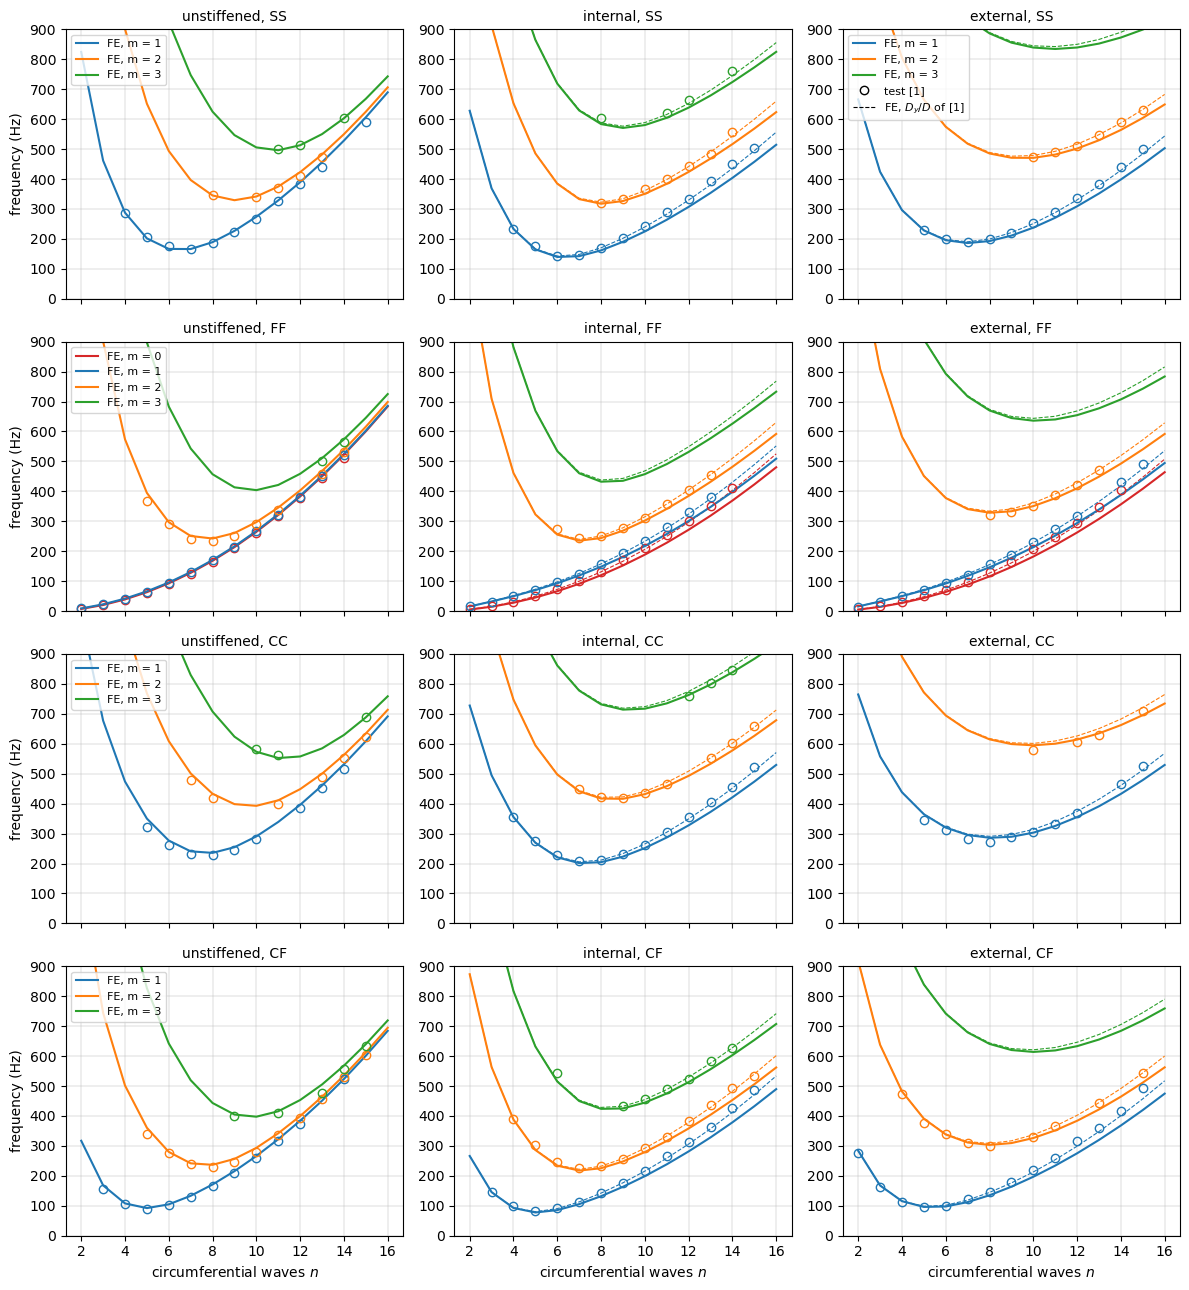

In [11]:
fig, axes = plt.subplots(4, 3, figsize=(12, 13), sharex=True)
colors = {0: 'C3', 1: 'C0', 2: 'C1', 3: 'C2'}
for row, bc in enumerate(['SS', 'FF', 'CC', 'CF']):
    for col, shell in enumerate(['unstiffened', 'internal', 'external']):
        ax = axes[row, col]
        freq = results[(shell, bc)][1]
        for m in sorted(set(mn[0] for mn in freq)):
            if m > 3:
                continue
            ns = sorted(n for (mm, n) in freq if mm == m)
            ax.plot(ns, [freq[(m, n)] for n in ns], '-', color=colors[m],
                    label='FE, m = %d' % m)
            if shell != 'unstiffened':
                fD = results_Dy[(shell, bc)]
                nsD = sorted(n for (mm, n) in fD if mm == m)
                ax.plot(nsD, [fD[(m, n)] for n in nsD], '--', lw=0.8,
                        color=colors[m])
        for (m, n), values in test[bc][shell].items():
            ax.plot([n], [reference(bc, m, values)], 'o', mfc='none',
                    color=colors[m])
        ax.set_ylim(0, 900)
        ax.grid(True, lw=0.3)
        ax.set_title('%s, %s' % (shell, bc), fontsize=10)
        if col == 0:
            ax.set_ylabel('frequency (Hz)')
        if row == 3:
            ax.set_xlabel('circumferential waves $n$')
    axes[row, 0].legend(loc='upper left', fontsize=8)
axes[0, 2].plot([], [], 'ko', mfc='none', label='test [1]')
axes[0, 2].plot([], [], 'k--', lw=0.8, label='FE, $D_y/D$ of [1]')
axes[0, 2].legend(loc='upper left', fontsize=8)
plt.tight_layout()
plt.show()

## Minimum frequencies, external against internal stringers

[1] (report page 19) summarizes the eccentricity effect by the minimum
frequencies of the ES cylinder, higher than those of the IS cylinder by
about 34 % (SS), 35 % (FF, for the modes with $m = 2$), 39 % (CC) and 21 %
(CF); it does not say whether these are measured or computed minima (the
measured minima of Tables II to V give the SS value, the others are probably
read from the analysis of Figures 8 to 11). The same ratios from the
measured minima of the tables and from the computed minima of the model:

In [12]:
published = {'SS': 34, 'FF': 35, 'CC': 39, 'CF': 21}
print('ends  family   test min IS / ES (Hz)   FE min IS / ES (Hz)   '
      'ES/IS - 1: [1]   test    FE')
for bc in ['SS', 'FF', 'CC', 'CF']:
    ratios = []
    out = []
    for source in ['test', 'FE']:
        mins = []
        for shell in ['internal', 'external']:
            if source == 'test':
                d = {mn: reference(bc, mn[0], v)
                     for mn, v in test[bc][shell].items()}
            else:
                d = results[(shell, bc)][1]
            d = {mn: f for mn, f in d.items()
                 if (mn[0] == 2 if bc == 'FF' else mn[0] >= 1)}
            mn = min(d, key=d.get)
            mins.append((mn, d[mn]))
        out.append('%5.1f %s / %5.1f %s' % (mins[0][1], mins[0][0],
                                            mins[1][1], mins[1][0]))
        ratios.append(100*(mins[1][1]/mins[0][1] - 1))
    print('%-4s  %-7s  %-22s  %-22s  %5d %%  %5.1f %%  %5.1f %%'
          % (bc, 'm = 2' if bc == 'FF' else 'all', *out, published[bc],
             *ratios))

ends  family   test min IS / ES (Hz)   FE min IS / ES (Hz)   ES/IS - 1: [1]   test    FE
SS    all      142.0 (1, 6) / 189.0 (1, 7)  139.7 (1, 6) / 186.2 (1, 7)     34 %   33.1 %   33.3 %
FF    m = 2    245.0 (2, 7) / 320.0 (2, 8)  235.3 (2, 7) / 328.5 (2, 8)     35 %   30.6 %   39.6 %
CC    all      207.0 (1, 7) / 272.0 (1, 8)  201.5 (1, 7) / 286.1 (1, 8)     39 %   31.4 %   42.0 %
CF    all       81.5 (1, 5) /  95.5 (1, 5)   77.7 (1, 5) /  96.2 (1, 5)     21 %   17.2 %   23.9 %


## Comparison with the discrete-stringer analysis of Egle and Sewall

Table 2 of [2] (page 523) gives the frequencies of the freely supported
cylinder with 60 external stringers computed with the stringers as discrete
elements and with the averaged-stiffener analysis, the latter "obtained
from Ref. 14 with in-surface and eccentricity inertia terms omitted" (Ref.
14 of [2] is the analysis of [1], then a proposed report). The discrete
analysis neglects the in-surface (in-plane) inertia of the shell too, which
makes the frequencies at small $n$ "somewhat higher than the correct
values" [2] (page 522). Their stringers are beams with the section
properties of Table 1 of [2] (from [1]), and the circumferential bending
stiffness of the skin is increased by the factor $D_y/D = 1.197$ for the
width of the stringer root and its fillets (Appendix A of [1]). The model is
compared with the plate stringers alone and with the factor $D_y/D$ of the
previous section. The value 44.53 Hz printed for $m = 1$, $n = 3$ (discrete) and
424.2 Hz for $m = 1$, $n = 12$ (averaged) break the trends of their columns
(445.1 and 322.8 Hz are their neighbours in the other column) and are
probably misprints; they are shown but left out of the statistics.

In [13]:
# Table 2 of [2], page 523: n: (m = 1 discrete, averaged, m = 2 discrete,
# averaged, m = 3 discrete, averaged), Hz
egle = {
    1: (1398., 1398., 1950., 1952., 2127., 2128.),
    2: (736.5, 736.3, 1428., 1429., 1810., 1810.),
    3: (44.53, 445.1, 1059., 1059., 1514., 1514.),
    4: (304.0, 303.9, 824.1, 823.9, 1291., 1290.),
    5: (231.8, 231.8, 674.8, 674.6, 1132., 1132.),
    6: (197.7, 197.9, 579.6, 579.5, 1022., 1021.),
    7: (188.2, 188.6, 520.3, 520.4, 945.5, 945.1),
    8: (196.0, 196.7, 486.2, 486.7, 894.7, 894.6),
    9: (216.1, 217.0, 471.1, 472.0, 862.9, 863.2),
    10: (245.2, 246.3, 470.8, 472.1, 846.1, 846.8),
    11: (281.2, 282.5, 482.5, 484.2, 841.4, 842.6),
    12: (322.8, 424.2, 504.2, 506.3, 846.9, 848.6),
    13: (369.3, 370.9, 534.5, 536.9, 861.3, 863.6),
    14: (420.2, 421.9, 572.1, 574.9, 883.6, 886.5),
    15: (475.2, 477.1, 616.2, 619.4, 913.2, 916.6),
}
misprints = {(1, 3, 'discrete'), (1, 12, 'averaged')}

model, freq_es, _ = spectrum('external', 'SS', final['SS'], ns=range(1, 16),
                            k=16)
freq_es_Dy = spectrum_Dy('external', 'SS', final['SS'], ns=range(1, 16),
                         k=16)
print(' m   n |  FE (Hz) FE D_y (Hz) | discrete [2]  diff   diff D_y | '
      'averaged [2]  diff   diff D_y')
diffs = {}
for m in [1, 2, 3]:
    for n in range(1, 16):
        fe = freq_es.get((m, n), np.nan)
        fe_Dy = freq_es_Dy.get((m, n), np.nan)
        row = '%2d %3d | %8.1f %8.1f    |' % (m, n, fe, fe_Dy)
        for j, kind in enumerate(['discrete', 'averaged']):
            ref = egle[n][2*(m - 1) + j]
            d, d_Dy = 100*(fe/ref - 1), 100*(fe_Dy/ref - 1)
            flag = ' misprint?' if (m, n, kind) in misprints else ''
            row += ' %9.1f %+7.1f %% %+7.1f %%%s |' % (ref, d, d_Dy, flag)
            if not flag and n >= 4:
                diffs.setdefault((kind, 'D_y/D = 1'), []).append(d)
                diffs.setdefault((kind, 'D_y/D = 1.197'), []).append(d_Dy)
        print(row)
for (kind, model_), d in diffs.items():
    print('n >= 4, %s [2], FE with %s: mean %+.1f %%, range %+.1f %% to '
          '%+.1f %%' % (kind, model_, np.nanmean(d), np.nanmin(d),
                        np.nanmax(d)))

 m   n |  FE (Hz) FE D_y (Hz) | discrete [2]  diff   diff D_y | averaged [2]  diff   diff D_y
 1   1 |   1117.8   1119.6    |    1398.0   -20.0 %   -19.9 % |    1398.0   -20.0 %   -19.9 % |
 1   2 |    666.0    666.3    |     736.5    -9.6 %    -9.5 % |     736.3    -9.6 %    -9.5 % |
 1   3 |    424.2    424.3    |      44.5  +852.6 %  +852.9 % misprint? |     445.1    -4.7 %    -4.7 % |
 1   4 |    296.3    296.6    |     304.0    -2.5 %    -2.4 % |     303.9    -2.5 %    -2.4 % |
 1   5 |    228.5    229.4    |     231.8    -1.4 %    -1.1 % |     231.8    -1.4 %    -1.1 % |
 1   6 |    195.8    197.9    |     197.7    -1.0 %    +0.1 % |     197.9    -1.1 %    +0.0 % |
 1   7 |    186.2    190.4    |     188.2    -1.1 %    +1.2 % |     188.6    -1.3 %    +0.9 % |
 1   8 |    192.9    199.7    |     196.0    -1.6 %    +1.9 % |     196.7    -2.0 %    +1.5 % |
 1   9 |    211.1    221.1    |     216.1    -2.3 %    +2.3 % |     217.0    -2.7 %    +1.9 % |
 1  10 |    237.7    251.2    | 

## Mode shapes

The normal displacement $w$ of the skin over the developed cylinder, rebuilt
from the sector by the factors $e^{i n k \phi}$, for the lowest measured
mode of each end condition, internal and external stringers; the stringers
are not drawn (60 lines at $6°$ spacing). The position along $x$ runs from
the bottom ($x = 0$, the clamped end for CF) to the top.

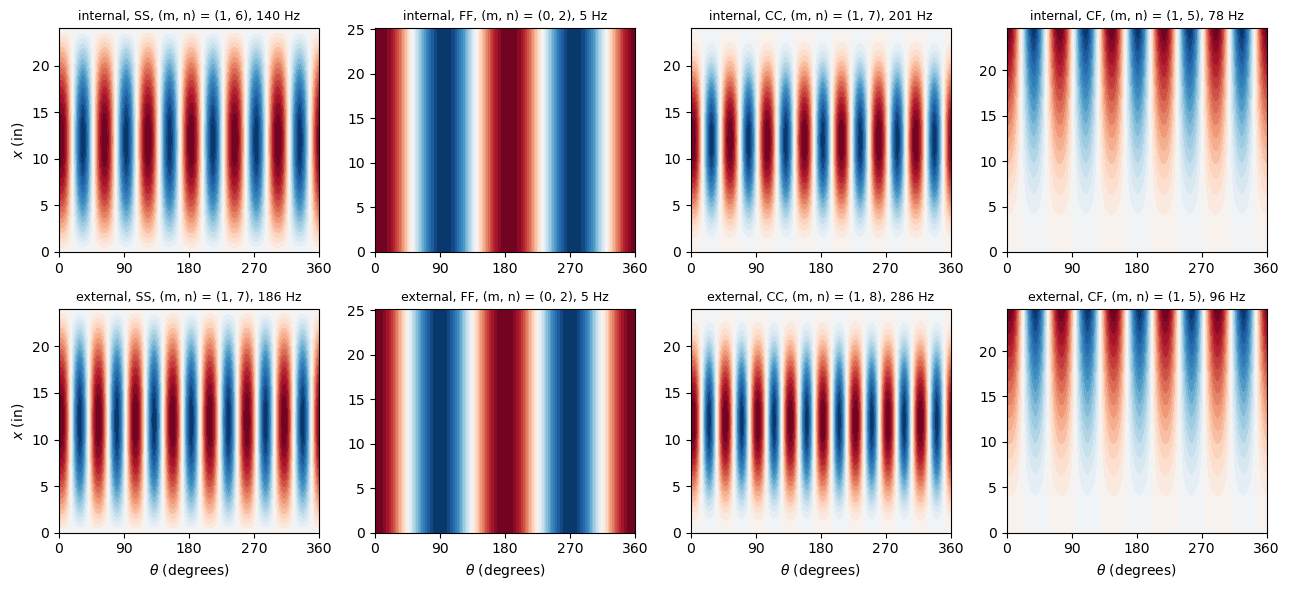

In [14]:
def plot_w(ax, model, mode, n, title):
    w = normalize_phase(model.skin_field(mode, W))
    theta, wfull = model.full_circumference(w, n)
    lim = np.abs(wfull).max()
    ax.contourf(np.degrees(theta), model.xlin, wfull,
                levels=np.linspace(-lim, lim, 31), cmap='RdBu_r')
    ax.set_title(title, fontsize=9)


fig, axes = plt.subplots(2, 4, figsize=(13, 6), sharey=False)
for row, shell in enumerate(['internal', 'external']):
    for col, bc in enumerate(['SS', 'FF', 'CC', 'CF']):
        model, freq, modes = results[(shell, bc)]
        d = {mn: f for mn, f in freq.items() if mn in test[bc][shell]}
        mn = min(d, key=d.get)
        plot_w(axes[row, col], model, modes[mn], mn[1],
               '%s, %s, (m, n) = %s, %.0f Hz' % (shell, bc, mn, d[mn]))
        axes[row, col].set_xticks([0, 90, 180, 270, 360])
for ax in axes[1]:
    ax.set_xlabel(r'$\theta$ (degrees)')
for ax in axes[:, 0]:
    ax.set_ylabel('$x$ (in)')
plt.tight_layout()
plt.show()

The cross-section at mid-length of the lowest SS modes, the skin (black) and
the 60 stringers (red), the displacements greatly magnified: the stringers
follow the radial displacement and the rotation of the skin at their root.

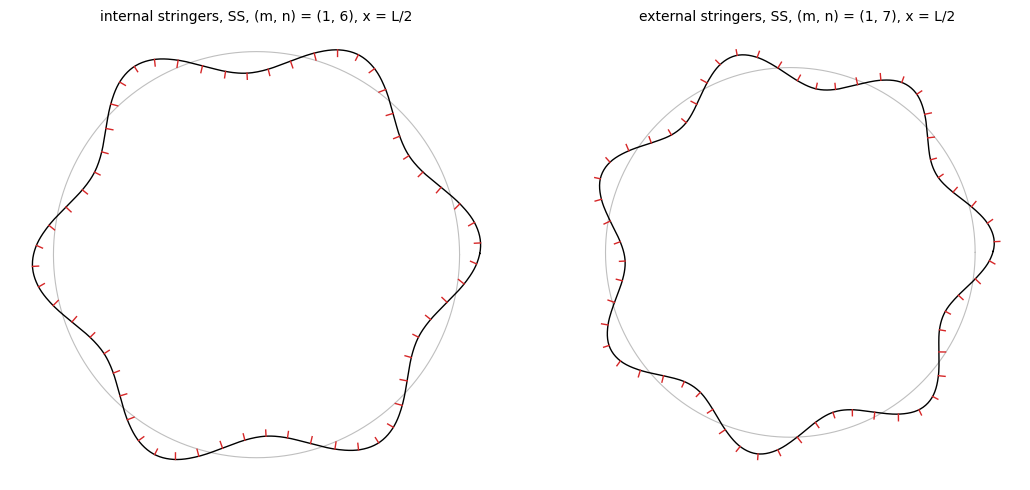

In [15]:
def plot_section(ax, model, mode, n, scale):
    i = model.nx//2
    R = model.R
    w = normalize_phase(mode)
    theta, wf = model.full_circumference(model.skin_field(w, W), n)
    _, vf = model.full_circumference(model.skin_field(w, V), n)
    norm = scale/np.abs(wf[i]).max()
    ax.plot(R*np.cos(theta), R*np.sin(theta), color='0.75', lw=0.8)
    r = R + norm*wf[i]
    t = theta + norm*vf[i]/R
    ax.plot(r*np.cos(t), r*np.sin(t), 'k', lw=1)
    nodes = model.str_nodes[i]
    r0 = R + model.Y
    for k in range(model.nstringers):
        ths = (k + 0.5)*model.phi
        fac = np.exp(1j*n*k*model.phi)
        Vs = np.real(w[DOF*nodes + V]*fac)
        Ws = np.real(w[DOF*nodes + W]*fac)
        r = r0 + norm*Vs
        t = ths + norm*Ws/r0
        ax.plot(r*np.cos(t), r*np.sin(t), 'C3', lw=1)
    ax.set_aspect('equal')
    ax.axis('off')


fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, shell in zip(axes, ['internal', 'external']):
    model, freq, modes = results[(shell, 'SS')]
    d = {mn: f for mn, f in freq.items() if mn in test['SS'][shell]}
    mn = min(d, key=d.get)
    plot_section(ax, model, modes[mn], mn[1], scale=1.)
    ax.set_title('%s stringers, SS, (m, n) = %s, x = L/2' % (shell, mn),
                 fontsize=10)
plt.tight_layout()
plt.show()

## Discussion

**Unstiffened cylinder.** The model reproduces the measured frequencies of
the unstiffened cylinder within a few per cent for the four end conditions
(statistics above), which validates the material data, the identification
of $(m, n)$ and the idealized end conditions. The model is stiffer than the
tests for CC and CF ends at small $n$ (up to about 8 %): the potted ends are
less rigid than a perfect clamp, and [1] (report page 18) attributes part of
its own differences for CC ends to "some external loading (due to the
potting of the ends) which could not be completely eliminated".

**Stiffened cylinders, stringers joined along a line.** With the plate
stringers alone, the model is below the tests by 3 % to 7 % on average
(except the externally stiffened cylinder with CC ends), and the difference
grows with $n$, to about $-10$ % for $m = 1$,
$n = 15$, and $-15$ % for the FF modes with $m = 0$. These are the modes
that bend the skin around the circumference, where the roots of the
stringers, 0.100 in wide with two fillets of radius 1/16 in, stiffen up to
0.225 in of each 1.00 in pitch, which the model represents by a skin of
uniform thickness $h$. The mesh is not the cause: the measured modes change
by less than 1 % between the two finest meshes.

**With the transverse bending stiffness of [1].** Increasing the
circumferential bending stiffness of the skin by the factors $D_y/D$ of
Appendix A of [1] removes most of that trend: the mean differences fall to
within about $\pm 3$ % for all eight cases, and the SS modes with $m = 1$
agree within $-5$ % to $+2$ %. This agrees with the summary of [1]:
"agreement between measured and calculated frequencies was significantly
improved when the analysis included local transverse bending stiffness due
to the stiffeners". The factor is a smeared correction; a model of the
roots themselves (a thicker skin strip under each stringer, or the fillets
as plate elements) would replace it and is not attempted here.

**Remaining differences.** With $D_y/D$, the largest differences are
those of the FF modes with $m = 0$ and small $n$, below the tests, and of
the CC ends of the externally stiffened cylinder, above the tests; [1]
(report page 20) also finds the closer agreement for the internally
stiffened cylinder with CC ends "not readily explainable, although the
externally stiffened shell may have been subjected to more external
loading". Other sources not modelled: the two longitudinal seams, the
fillets as mass, the departures of the measured dimensions from their
averages (Table I gives averages), and for the SS ends the knife edges,
which did not restrain the normal displacement between the stringers on the
stiffened side (report page 7), while the model restrains it along the whole
edge.

**Eccentricity.** The external stringers raise the minimum frequencies
above those of the internal stringers in the model as in the tests. For SS
ends the ratio of the minima agrees with the tests and with the 34 % of
[1]; for FF ($m = 2$), CC and CF ends the model gives larger ratios than
the measured minima: closer to the values quoted by [1] for CC and CF ends,
about as far above the 35 % of [1] for FF ($m = 2$) as the measured minima
are below it.

**Discrete-stringer analysis of [2].** For $n \ge 4$ the model with
$D_y/D$ is close to Table 2 of [2], which uses the same $D_y/D$; the
remaining differences come from the stringer model (beams with the section
properties of Table 1 of [2] against plates). For $n \le 3$ the model is
well below [2], up to 20 % for $n = 1$: [2] neglects the in-surface
inertia of the skin, which, as [2] states, makes its frequencies at small
$n$ too high, and the model includes it; the difference decreases with
$m$, to about $-4$ % for $m = 3$, $n = 1$.